In [4]:

import mysql.connector
import pandas as pd
import numpy as np

from mysql.connector import Error
from sklearn.cluster import MiniBatchKMeans

# --------------------------------
# CONFIGURATION
# --------------------------------

TABLE_NAME = "labeled_flatdata"

BATCH_SIZE = 10000
N_CLUSTERS = 15

# --------------------------------
# MYSQL CONNECTION
# --------------------------------

def get_connection():
    return mysql.connector.connect(
        host="localhost",
        user="root",
        password="",
        database="marketdata",
    )


# --------------------------------
# OHLC FEATURES
# --------------------------------

features = []

for timeframe in ["H4", "H1", "M15", "M5"]:
    for i in range(1, 21):
        for price in ["open", "high", "low", "close"]:
            features.append(
                f"{timeframe}_{i:02d}_{price}"
            )

assert len(features) == 320

columns_sql = ", ".join(
    f"`{c}`" for c in features
)

# --------------------------------
# MINI BATCH KMEANS
# --------------------------------

model = MiniBatchKMeans(
    n_clusters=N_CLUSTERS,
    batch_size=BATCH_SIZE,
    random_state=42,
    n_init=3,
    max_iter=100,
    reassignment_ratio=0.01
)

connection = get_connection()

if not connection.is_connected():
    raise Exception("MySQL connection failed")

cursor = connection.cursor()

cursor.execute(
    f"SELECT COUNT(*) FROM `{TABLE_NAME}`"
)

total_rows = cursor.fetchone()[0]

print("Total database rows:", total_rows)

# --------------------------------
# PASS 1: INCREMENTAL TRAINING
# --------------------------------

query = f"""
SELECT `id`, {columns_sql}
FROM `{TABLE_NAME}`
ORDER BY `id`
"""

cursor.execute(query)

valid_rows = 0
invalid_rows = 0
batch_number = 0

while True:

    rows = cursor.fetchmany(BATCH_SIZE)

    if not rows:
        break

    data = pd.DataFrame(
        rows,
        columns=["id"] + features
    )

    ids = data["id"].to_numpy()

    X = data[features].to_numpy(
        dtype=np.float32
    )

    valid = np.isfinite(X).all(axis=1)

    X = X[valid]

    if len(X) == 0:
        invalid_rows += len(rows)
        continue

    model.partial_fit(X)

    valid_rows += len(X)
    invalid_rows += len(rows) - len(X)
    batch_number += 1

    print(
        f"Training batch {batch_number} | "
        f"Valid rows: {valid_rows}"
    )

print("\nTraining complete")
print("Valid rows:", valid_rows)
print("Invalid rows:", invalid_rows)

cursor.close()
connection.close()

# --------------------------------
# PASS 2: ASSIGN CLUSTERS
# --------------------------------

connection = get_connection()
cursor = connection.cursor()

cursor.execute(query)

output_file = open(
    "ohlc_cluster_results.csv",
    "w",
    encoding="utf-8"
)

output_file.write("id,cluster\n")

while True:

    rows = cursor.fetchmany(BATCH_SIZE)

    if not rows:
        break

    data = pd.DataFrame(
        rows,
        columns=["id"] + features
    )

    ids = data["id"].to_numpy()

    X = data[features].to_numpy(
        dtype=np.float32
    )

    valid = np.isfinite(X).all(axis=1)

    if not valid.any():
        continue

    labels = model.predict(X[valid])

    result = pd.DataFrame({
        "id": ids[valid],
        "cluster": labels
    })

    result.to_csv(
        output_file,
        index=False,
        header=False
    )

    print(
        "Assigned clusters:",
        len(result)
    )

output_file.close()
cursor.close()
connection.close()

print("\nAll clustering assignments saved!")

# --------------------------------
# SAVE MODEL
# --------------------------------

import joblib

joblib.dump(
    model,
    "ohlc_minibatch_kmeans.pkl"
)

print("Model saved successfully")


Total database rows: 512485
Training batch 1 | Valid rows: 10000
Training batch 2 | Valid rows: 20000
Training batch 3 | Valid rows: 30000
Training batch 4 | Valid rows: 40000
Training batch 5 | Valid rows: 50000
Training batch 6 | Valid rows: 60000
Training batch 7 | Valid rows: 70000
Training batch 8 | Valid rows: 80000
Training batch 9 | Valid rows: 90000
Training batch 10 | Valid rows: 100000
Training batch 11 | Valid rows: 110000
Training batch 12 | Valid rows: 120000
Training batch 13 | Valid rows: 130000
Training batch 14 | Valid rows: 140000
Training batch 15 | Valid rows: 150000
Training batch 16 | Valid rows: 160000
Training batch 17 | Valid rows: 170000
Training batch 18 | Valid rows: 180000
Training batch 19 | Valid rows: 190000
Training batch 20 | Valid rows: 200000
Training batch 21 | Valid rows: 210000
Training batch 22 | Valid rows: 220000
Training batch 23 | Valid rows: 230000
Training batch 24 | Valid rows: 240000
Training batch 25 | Valid rows: 250000
Training batch 

In [2]:

import pandas as pd
import numpy as np
import joblib

# Load results and trained model
results = pd.read_csv("ohlc_cluster_results.csv")
model = joblib.load("ohlc_minibatch_kmeans.pkl")

# Cluster distribution
distribution = (
    results["cluster"]
    .value_counts()
    .sort_index()
    .rename("rows")
    .to_frame()
)

distribution["percentage"] = (
    distribution["rows"] / len(results) * 100
)

print("\nCLUSTER DISTRIBUTION")
print(distribution.round(2))

print("\nCLUSTER CENTERS")
print(model.cluster_centers_.shape)

# Export cluster distribution
distribution.to_csv("cluster_distribution.csv")

print("\nTotal clusters:", results["cluster"].nunique())
print("Total assigned rows:", len(results))



CLUSTER DISTRIBUTION
          rows  percentage
cluster                   
0        31683        6.18
1        21911        4.28
2        17353        3.39
3        67659       13.20
4        21506        4.20
5        46984        9.17
6        40939        7.99
7        19712        3.85
8        36168        7.06
9        42896        8.37
10       23804        4.64
11       42276        8.25
12       26305        5.13
13       10107        1.97
14       63182       12.33

CLUSTER CENTERS
(15, 320)

Total clusters: 15
Total assigned rows: 512485


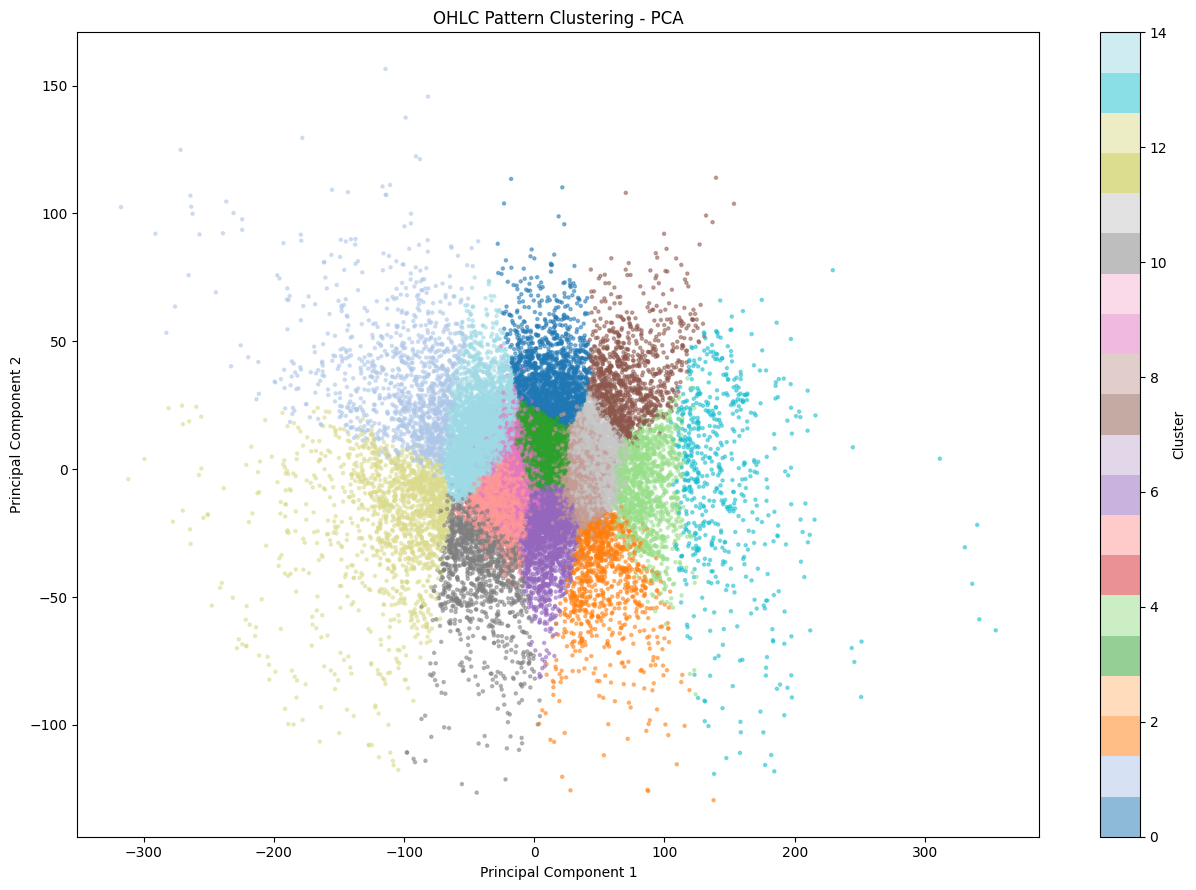

Explained variance: 0.82125235


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.decomposition import PCA

# Load trained model and cluster assignments
model = joblib.load("ohlc_minibatch_kmeans.pkl")

results = pd.read_csv("ohlc_cluster_results.csv")

# Use a representative sample of 30,000 rows
sample = results.sample(
    n=min(30000, len(results)),
    random_state=42
)

# Fetch corresponding original OHLC rows
connection = get_connection()
cursor = connection.cursor()

ids = sample["id"].tolist()

# Fetch in manageable chunks
features = []

for timeframe in ["H4", "H1", "M15", "M5"]:
    for i in range(1, 21):
        for price in ["open", "high", "low", "close"]:
            features.append(
                f"{timeframe}_{i:02d}_{price}"
            )

columns_sql = ", ".join(
    f"`{c}`" for c in features
)

frames = []

for start in range(0, len(ids), 1000):

    chunk = ids[start:start + 1000]

    placeholders = ",".join(["%s"] * len(chunk))

    query = f"""
    SELECT `id`, {columns_sql}
    FROM labeled_flatdata
    WHERE id IN ({placeholders})
    """

    cursor.execute(query, chunk)

    rows = cursor.fetchall()

    frames.append(
        pd.DataFrame(
            rows,
            columns=["id"] + features
        )
    )

cursor.close()
connection.close()

data = pd.concat(frames, ignore_index=True)

# Preserve cluster assignment by database ID
data = data.merge(
    sample[["id", "cluster"]],
    on="id"
)

X = data[features].to_numpy(dtype="float32")

# PCA
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X)

# Visualization
plt.figure(figsize=(13, 9))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data["cluster"],
    cmap="tab20",
    s=5,
    alpha=0.5
)

plt.colorbar(scatter, label="Cluster")

plt.title("OHLC Pattern Clustering - PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.savefig("ohlc_pca_clusters.png", dpi=200)
plt.show()

print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)


In [4]:

import pandas as pd
import numpy as np
import joblib

from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Load cluster results
results = pd.read_csv("ohlc_cluster_results.csv")

# Load model
model = joblib.load("ohlc_minibatch_kmeans.pkl")

# Get representative sample
sample = results.sample(
    n=min(10000, len(results)),
    random_state=42
)

# Fetch the sample's OHLC values
connection = get_connection()

features = [
    f"{tf}_{i:02d}_{price}"
    for tf in ["H4", "H1", "M15", "M5"]
    for i in range(1, 21)
    for price in ["open", "high", "low", "close"]
]

columns = ", ".join(f"`{c}`" for c in features)

frames = []

for start in range(0, len(sample), 1000):

    ids = sample["id"].iloc[start:start+1000].tolist()

    placeholders = ",".join(["%s"] * len(ids))

    query = f"""
    SELECT id, {columns}
    FROM labeled_flatdata
    WHERE id IN ({placeholders})
    """

    chunk = pd.read_sql(
        query,
        connection,
        params=ids
    )

    frames.append(chunk)

connection.close()

data = pd.concat(frames, ignore_index=True)

data = data.merge(
    sample[["id", "cluster"]],
    on="id"
)

X = data[features].to_numpy(dtype=np.float32)
labels = data["cluster"].to_numpy()

# PCA with 10 components
pca = PCA(n_components=10)

X_pca = pca.fit_transform(X)

print("\nPCA VARIANCE")
print("10 components:", pca.explained_variance_ratio_.sum())

# Clustering quality
print("\nCLUSTER QUALITY")

print(
    "Silhouette:",
    silhouette_score(X, labels)
)

print(
    "Davies-Bouldin:",
    davies_bouldin_score(X, labels)
)

print(
    "Calinski-Harabasz:",
    calinski_harabasz_score(X, labels)
)

# Cluster-center similarity
centers = model.cluster_centers_

from sklearn.metrics.pairwise import euclidean_distances

distances = euclidean_distances(centers)

np.fill_diagonal(distances, np.inf)

print("\nCLOSEST CLUSTER CENTERS")

for i in range(len(centers)):

    nearest = np.argmin(distances[i])

    print(
        f"Cluster {i} closest to Cluster {nearest}: "
        f"{distances[i, nearest]:.6f}"
    )


C:\Users\nishw\AppData\Local\Temp\ipykernel_6424\307868931.py:50: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  chunk = pd.read_sql(



PCA VARIANCE
10 components: 0.9559708

CLUSTER QUALITY
Silhouette: 0.09040925651788712
Davies-Bouldin: 1.8243627196720056
Calinski-Harabasz: 1811.177978515625

CLOSEST CLUSTER CENTERS
Cluster 0 closest to Cluster 3: 28.204224
Cluster 1 closest to Cluster 12: 51.766140
Cluster 2 closest to Cluster 6: 46.133018
Cluster 3 closest to Cluster 9: 27.820658
Cluster 4 closest to Cluster 11: 43.670315
Cluster 5 closest to Cluster 9: 24.814049
Cluster 6 closest to Cluster 3: 29.342207
Cluster 7 closest to Cluster 11: 38.406799
Cluster 8 closest to Cluster 11: 24.513445
Cluster 9 closest to Cluster 5: 24.814049
Cluster 10 closest to Cluster 5: 32.070415
Cluster 11 closest to Cluster 8: 24.513445
Cluster 12 closest to Cluster 1: 51.766140
Cluster 13 closest to Cluster 4: 54.071220
Cluster 14 closest to Cluster 5: 30.988602


In [5]:

import pandas as pd
import numpy as np

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# --------------------------------
# LOAD SAMPLE OHLC DATA
# --------------------------------

results = pd.read_csv("ohlc_cluster_results.csv")

sample = results.sample(
    n=min(30000, len(results)),
    random_state=42
)

connection = get_connection()

features = [
    f"{tf}_{i:02d}_{price}"
    for tf in ["H4", "H1", "M15", "M5"]
    for i in range(1, 21)
    for price in ["open", "high", "low", "close"]
]

columns = ", ".join(f"`{c}`" for c in features)

frames = []

for start in range(0, len(sample), 1000):

    ids = sample["id"].iloc[start:start+1000].tolist()

    placeholders = ",".join(["%s"] * len(ids))

    query = f"""
    SELECT id, {columns}
    FROM labeled_flatdata
    WHERE id IN ({placeholders})
    """

    frames.append(
        pd.read_sql(query, connection, params=ids)
    )

connection.close()

data = pd.concat(frames, ignore_index=True)

data = data.merge(
    sample[["id", "cluster"]],
    on="id"
)

X = data[features].to_numpy(dtype=np.float32)

# --------------------------------
# PCA
# --------------------------------

pca = PCA(
    n_components=10,
    random_state=42
)

X_pca = pca.fit_transform(X)

print(
    "PCA variance:",
    pca.explained_variance_ratio_.sum()
)

# --------------------------------
# TEST DIFFERENT CLUSTER COUNTS
# --------------------------------

results_pca = []

for k in [5, 8, 10, 15, 20, 30]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    silhouette = silhouette_score(
        X_pca,
        labels,
        sample_size=10000,
        random_state=42
    )

    db_score = davies_bouldin_score(
        X_pca,
        labels
    )

    ch_score = calinski_harabasz_score(
        X_pca,
        labels
    )

    results_pca.append({
        "K": k,
        "Silhouette": silhouette,
        "Davies_Bouldin": db_score,
        "Calinski_Harabasz": ch_score
    })

    print(
        f"K={k} | "
        f"Silhouette={silhouette:.4f} | "
        f"DB={db_score:.4f} | "
        f"CH={ch_score:.2f}"
    )

comparison = pd.DataFrame(results_pca)

comparison.to_csv(
    "pca_kmeans_comparison.csv",
    index=False
)

print("\nFINAL COMPARISON")
print(comparison.to_string(index=False))


C:\Users\nishw\AppData\Local\Temp\ipykernel_24992\2076995167.py:49: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pd.read_sql(query, connection, params=ids)


PCA variance: 0.9561534
K=5 | Silhouette=0.1992 | DB=1.3789 | CH=12839.54
K=8 | Silhouette=0.1829 | DB=1.3674 | CH=10111.98
K=10 | Silhouette=0.1646 | DB=1.3750 | CH=8938.63
K=15 | Silhouette=0.1487 | DB=1.4056 | CH=7069.02
K=20 | Silhouette=0.1328 | DB=1.5035 | CH=5918.19
K=30 | Silhouette=0.1188 | DB=1.5384 | CH=4591.32

FINAL COMPARISON
 K  Silhouette  Davies_Bouldin  Calinski_Harabasz
 5    0.199165        1.378862       12839.541016
 8    0.182887        1.367358       10111.981445
10    0.164634        1.375014        8938.634766
15    0.148694        1.405569        7069.019531
20    0.132794        1.503482        5918.190430
30    0.118835        1.538363        4591.321777


In [2]:

import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

dimensions = [5, 10, 15, 20, 30, 50]
cluster_counts = [5, 8, 10, 15]

experiment_results = []

for n_components in dimensions:

    print(f"\nTesting PCA dimensions: {n_components}")

    pca = PCA(
        n_components=n_components,
        random_state=42
    )

    X_reduced = pca.fit_transform(X)

    variance = pca.explained_variance_ratio_.sum()

    for k in cluster_counts:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_reduced)

        silhouette = silhouette_score(
            X_reduced,
            labels,
            sample_size=10000,
            random_state=42
        )

        db = davies_bouldin_score(
            X_reduced,
            labels
        )

        ch = calinski_harabasz_score(
            X_reduced,
            labels
        )

        experiment_results.append({
            "PCA_Dimensions": n_components,
            "Variance": variance,
            "K": k,
            "Silhouette": silhouette,
            "Davies_Bouldin": db,
            "Calinski_Harabasz": ch
        })

        print(
            f"Dimensions={n_components}, K={k}, "
            f"Silhouette={silhouette:.4f}, DB={db:.4f}"
        )

comparison = pd.DataFrame(experiment_results)

comparison.to_csv(
    "pca_dimension_experiments.csv",
    index=False
)

print("\nFINAL RESULTS")

print(
    comparison.sort_values(
        "Silhouette",
        ascending=False
    ).to_string(index=False)
)



Testing PCA dimensions: 5


NameError: name 'X' is not defined

In [6]:

import hdbscan
import pandas as pd
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use your existing 30K OHLC sample X

pca = PCA(
    n_components=5,
    random_state=42
)

X_pca = pca.fit_transform(X)

print("PCA variance:", pca.explained_variance_ratio_.sum())

results = []

# Test different density settings
for min_cluster_size in [100, 250, 500, 1000]:

    for min_samples in [10, 25, 50]:

        model = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric="euclidean",
            cluster_selection_method="eom",
            core_dist_n_jobs=-1
        )

        labels = model.fit_predict(X_pca)

        valid = labels != -1

        n_clusters = len(set(labels[valid]))
        noise_pct = 100 * (~valid).mean()

        if n_clusters < 2 or valid.sum() < 100:
            continue

        X_valid = X_pca[valid]
        labels_valid = labels[valid]

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(10000, len(X_valid)),
            random_state=42
        )

        db = davies_bouldin_score(
            X_valid,
            labels_valid
        )

        ch = calinski_harabasz_score(
            X_valid,
            labels_valid
        )

        results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_pct": noise_pct,
            "silhouette": silhouette,
            "davies_bouldin": db,
            "calinski_harabasz": ch
        })

        print(
            f"MCS={min_cluster_size}, "
            f"MS={min_samples}, "
            f"Clusters={n_clusters}, "
            f"Noise={noise_pct:.2f}%, "
            f"Silhouette={silhouette:.4f}, "
            f"DB={db:.4f}"
        )

comparison = pd.DataFrame(results)

comparison.to_csv(
    "hdbscan_comparison.csv",
    index=False
)

print("\nFINAL HDBSCAN RESULTS")

if not comparison.empty:
    print(
        comparison.sort_values(
            "silhouette",
            ascending=False
        ).to_string(index=False)
    )


PCA variance: 0.9193729


TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.